[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/shuishen112/neural-networks/blob/main/solutions/08_transformers_solutions.ipynb)

# Exercises 8 — Attention and Transformers

Fill in every cell marked `# YOUR CODE HERE` and answer the written questions.
The `assert` cells check your work: if a cell runs without an error, you are
probably on the right track. Everything runs on a CPU in a couple of minutes.

**Mask convention used throughout:** a boolean mask with `True` means *"this query is allowed
to attend to this key"* — the same as `F.scaled_dot_product_attention`.

In [1]:
import math

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(2)

## Exercise 8.1 — Masks

1. `causal_mask(T)` returns a `(T, T)` boolean tensor with `True` where key position $j$ is
   allowed for query position $t$, i.e. $j \le t$.
2. `padding_mask(lengths, S)` takes a `(B,)` tensor of true sequence lengths and returns a boolean
   tensor of shape `(B, 1, 1, S)` that is `True` for real (non-padded) key positions. The two
   singleton dimensions let it broadcast over heads and queries.

Do not use Python loops.

In [2]:
def causal_mask(T):
    return torch.tril(torch.ones(T, T, dtype=torch.bool))


def padding_mask(lengths, S):
    return (torch.arange(S)[None, :] < lengths[:, None])[:, None, None, :]

In [3]:
m = causal_mask(4)
assert m.dtype == torch.bool and m.shape == (4, 4)
assert torch.equal(m, torch.tensor([[1, 0, 0, 0], [1, 1, 0, 0], [1, 1, 1, 0], [1, 1, 1, 1]], dtype=torch.bool))
pm = padding_mask(torch.tensor([3, 1, 5]), 5)
assert pm.dtype == torch.bool and pm.shape == (3, 1, 1, 5)
assert torch.equal(pm[:, 0, 0].int(), torch.tensor([[1, 1, 1, 0, 0], [1, 0, 0, 0, 0], [1, 1, 1, 1, 1]], dtype=torch.int32))
print("masks OK")

masks OK


## Exercise 8.2 — Scaled dot-product attention

Implement

$$\operatorname{Attention}(Q,K,V) = \operatorname{softmax}\Big(\frac{QK^\top}{\sqrt{d_k}}\Big)V$$

for inputs `q` of shape `(..., T, d_k)`, `k` of shape `(..., S, d_k)` and `v` of shape `(..., S, d_v)`
(any number of leading batch dimensions). If a boolean `mask` (broadcastable to `(..., T, S)`) is
given, positions where it is `False` must receive **zero** weight — set their scores to
`float("-inf")` before the softmax (`Tensor.masked_fill`). Return the output `(..., T, d_v)` and
the attention weights `(..., T, S)`.

Add `assert` statements that check the shapes of the inputs are compatible (same $d_k$ for `q`
and `k`, same $S$ for `k` and `v`). We compare against `F.scaled_dot_product_attention`.

In [4]:
def attention(q, k, v, mask=None):
    assert q.shape[-1] == k.shape[-1], "q and k must have the same d_k"
    assert k.shape[-2] == v.shape[-2], "k and v must have the same number of positions"
    scores = q @ k.transpose(-2, -1) / math.sqrt(q.shape[-1])
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    return weights @ v, weights

In [5]:
torch.manual_seed(0)
q, k, v = torch.randn(2, 3, 5, 8), torch.randn(2, 3, 7, 8), torch.randn(2, 3, 7, 4)
out, w = attention(q, k, v)
assert out.shape == (2, 3, 5, 4) and w.shape == (2, 3, 5, 7)
assert torch.allclose(w.sum(-1), torch.ones(2, 3, 5), atol=1e-6)
assert torch.allclose(out, F.scaled_dot_product_attention(q, k, v), atol=1e-5)

# With a causal mask (self-attention, T = S).
x = torch.randn(2, 3, 6, 8)
out_c, w_c = attention(x, x, x, causal_mask(6))
assert torch.allclose(out_c, F.scaled_dot_product_attention(x, x, x, attn_mask=causal_mask(6)), atol=1e-5)
assert torch.allclose(out_c, F.scaled_dot_product_attention(x, x, x, is_causal=True), atol=1e-5)
assert (w_c.masked_select(~causal_mask(6)) == 0).all(), "masked positions must get exactly zero weight"

# With a padding mask.
pm = padding_mask(torch.tensor([7, 3]), 7)
out_p, w_p = attention(q, k, v, pm)
assert torch.allclose(out_p, F.scaled_dot_product_attention(q, k, v, attn_mask=pm), atol=1e-5)
assert (w_p[1, :, :, 3:] == 0).all()

# Shape checks.
try:
    attention(torch.randn(5, 8), torch.randn(7, 6), torch.randn(7, 4))
    raise RuntimeError("expected an AssertionError for mismatched d_k")
except AssertionError:
    pass
print("attention OK")

attention OK


## Exercise 8.3 — Multi-head self-attention

Complete `forward` of the module below. With $h$ heads and $d_k = d_{\text{model}}/h$:

1. project `x` of shape `(B, T, d_model)` with `self.in_proj` and split the result into $Q, K, V$
   (in that order, each `(B, T, d_model)`),
2. reshape each to `(B, h, T, d_k)`,
3. apply your `attention` (passing on the mask),
4. merge the heads back to `(B, T, d_model)` and apply `self.out_proj`.

Return the output and the attention weights `(B, h, T, T)`. Use `assert`s to check the shapes of
intermediate tensors. The parameter layout matches `nn.MultiheadAttention`, which we use as a reference
(note that **its** `attn_mask` uses the opposite convention: `True` = *not* allowed).

In [6]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.d_model, self.n_heads, self.d_k = d_model, n_heads, d_model // n_heads
        self.in_proj = nn.Linear(d_model, 3 * d_model)
        self.out_proj = nn.Linear(d_model, d_model)

    def forward(self, x, mask=None):
        B, T, D = x.shape
        assert D == self.d_model
        q, k, v = self.in_proj(x).chunk(3, dim=-1)
        q, k, v = [t.reshape(B, T, self.n_heads, self.d_k).transpose(1, 2) for t in (q, k, v)]
        assert q.shape == (B, self.n_heads, T, self.d_k)
        out, weights = attention(q, k, v, mask)
        assert out.shape == (B, self.n_heads, T, self.d_k)
        out = out.transpose(1, 2).reshape(B, T, D)
        return self.out_proj(out), weights

In [7]:
torch.manual_seed(0)
d_model, n_heads, T = 32, 4, 9
ref = nn.MultiheadAttention(d_model, n_heads, batch_first=True)
mha = MultiHeadSelfAttention(d_model, n_heads)
with torch.no_grad():
    mha.in_proj.weight.copy_(ref.in_proj_weight)
    mha.in_proj.bias.copy_(ref.in_proj_bias)
    mha.out_proj.weight.copy_(ref.out_proj.weight)
    mha.out_proj.bias.copy_(ref.out_proj.bias)

x = torch.randn(3, T, d_model)
with torch.no_grad():
    y, w = mha(x)
    y_ref, w_ref = ref(x, x, x, need_weights=True, average_attn_weights=False)
    assert y.shape == (3, T, d_model) and w.shape == (3, n_heads, T, T)
    assert torch.allclose(y, y_ref, atol=1e-5) and torch.allclose(w, w_ref, atol=1e-5)

    y_c, _ = mha(x, causal_mask(T))
    y_c_ref, _ = ref(x, x, x, attn_mask=~causal_mask(T))      # opposite convention!
    assert torch.allclose(y_c, y_c_ref, atol=1e-5)
print("multi-head attention OK")

multi-head attention OK


## Exercise 8.4 — Sinusoidal positional encoding

Implement `sinusoidal_pe(n_pos, d)` returning a `(n_pos, d)` float tensor with

$$p_{t,2i} = \sin\big(t\,/\,10000^{2i/d}\big), \qquad p_{t,2i+1} = \cos\big(t\,/\,10000^{2i/d}\big).$$

The checks below test the values and three properties: every row has norm $\sqrt{d/2}$, the
dot product $\mathbf{p}_t^\top\mathbf{p}_{t+k}$ depends only on $k$, and all positions get distinct
encodings.

In [8]:
def sinusoidal_pe(n_pos, d):
    assert d % 2 == 0
    pos = torch.arange(n_pos, dtype=torch.float32)[:, None]
    inv_freq = 1.0 / (10000.0 ** (torch.arange(0, d, 2, dtype=torch.float32) / d))
    pe = torch.zeros(n_pos, d)
    pe[:, 0::2] = torch.sin(pos * inv_freq)
    pe[:, 1::2] = torch.cos(pos * inv_freq)
    return pe

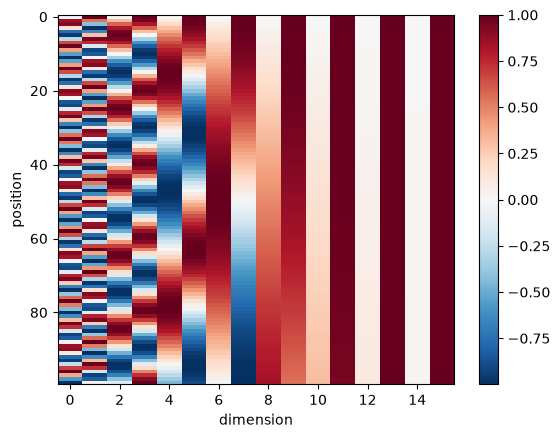

positional encoding OK


In [9]:
pe = sinusoidal_pe(100, 16)
assert pe.shape == (100, 16) and pe.dtype == torch.float32
assert torch.allclose(pe[0], torch.tensor([0.0, 1.0] * 8))
assert abs(pe[3, 0].item() - math.sin(3)) < 1e-6 and abs(pe[3, 1].item() - math.cos(3)) < 1e-6
assert abs(pe[7, 4].item() - math.sin(7 / 10000 ** (4 / 16))) < 1e-6
assert abs(pe[7, 5].item() - math.cos(7 / 10000 ** (4 / 16))) < 1e-6
# 1) constant norm
assert torch.allclose(pe.norm(dim=1), torch.full((100,), math.sqrt(8.0)), atol=1e-4)
# 2) dot products depend only on the offset
G = pe @ pe.T
for kk in [1, 5, 20]:
    diag = torch.diagonal(G, offset=kk)
    assert torch.allclose(diag, diag[0].expand_as(diag), atol=1e-3), kk
# 3) distinct encodings
D = torch.cdist(pe, pe) + torch.eye(100) * 1e3
assert D.min() > 0.1
plt.imshow(pe.numpy(), aspect="auto", cmap="RdBu_r"); plt.xlabel("dimension"); plt.ylabel("position")
plt.colorbar(); plt.show()
print("positional encoding OK")

## Exercise 8.5 — A Transformer block, and a small task

**(a)** Implement a **pre-LN** Transformer block,

$$X' = X + \operatorname{MHA}(\operatorname{LN}_1(X)), \qquad Y = X' + \operatorname{MLP}(\operatorname{LN}_2(X')),$$

with $\operatorname{MLP}(\mathbf{z}) = W_2\,\operatorname{GELU}(W_1\mathbf{z}+\mathbf{b}_1)+\mathbf{b}_2$ and hidden size `d_ff`. Use
your `MultiHeadSelfAttention`. The forward pass takes an optional mask and returns `(B, T, d_model)`.

In [10]:
class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, d_ff):
        super().__init__()
        self.ln1 = nn.LayerNorm(d_model)
        self.attn = MultiHeadSelfAttention(d_model, n_heads)
        self.ln2 = nn.LayerNorm(d_model)
        self.mlp = nn.Sequential(nn.Linear(d_model, d_ff), nn.GELU(), nn.Linear(d_ff, d_model))

    def forward(self, x, mask=None):
        x = x + self.attn(self.ln1(x), mask)[0]
        x = x + self.mlp(self.ln2(x))
        return x

In [11]:
torch.manual_seed(0)
blk = TransformerBlock(32, 4, 64)
x = torch.randn(2, 10, 32)
y = blk(x)
assert y.shape == x.shape
n_params = sum(p.numel() for p in blk.parameters())
expected = 2 * (2 * 32) + (32 * 96 + 96) + (32 * 32 + 32) + (32 * 64 + 64) + (64 * 32 + 32)
assert n_params == expected, (n_params, expected)
# With a causal mask, outputs at position t must not depend on inputs after t.
x2 = x.clone(); x2[:, 6:] = torch.randn(2, 4, 32)
with torch.no_grad():
    assert torch.allclose(blk(x, causal_mask(10))[:, :6], blk(x2, causal_mask(10))[:, :6], atol=1e-5)
    assert not torch.allclose(blk(x)[:, :6], blk(x2)[:, :6], atol=1e-5)
print("Transformer block OK")

Transformer block OK


**(b) Sorting digits.** Each input is a sequence of 8 random digits; the target at every position
is the **sorted** sequence. Build a small encoder-only model — token embedding + positional
encoding (your sinusoidal one or a learned `nn.Embedding`), two of your `TransformerBlock`s
(no mask), a final `nn.LayerNorm` and a linear head to 10 classes — and train it with AdamW on
batches from `sort_batch`. Reach a **per-token accuracy of at least 85 %** on the test set.
A model with $d_{\text{model}}=64$, 4 heads and around 2 000–2 500 steps of batch size 128 is enough.

Store the model in `sorter`; it must map a `(B, 8)` `LongTensor` to logits `(B, 8, 10)`.

In [12]:
L_SORT = 8

def sort_batch(B, gen):
    x = torch.randint(0, 10, (B, L_SORT), generator=gen)
    return x, x.sort(dim=1).values

gen = torch.Generator().manual_seed(0)
xb, yb = sort_batch(2, gen)
print(xb); print(yb)

tensor([[4, 9, 3, 0, 3, 9, 7, 3],
        [7, 3, 1, 6, 6, 9, 8, 6]])
tensor([[0, 3, 3, 3, 4, 7, 9, 9],
        [1, 3, 6, 6, 6, 7, 8, 9]])


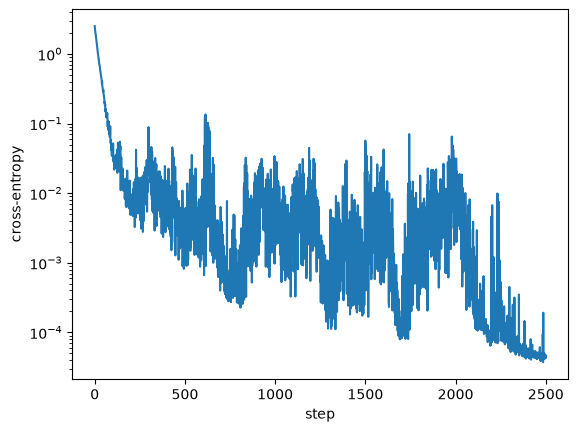

In [13]:
torch.manual_seed(0)
gen = torch.Generator().manual_seed(1)
class Sorter(nn.Module):
    def __init__(self, d_model=64, n_heads=4, d_ff=256, n_layers=2):
        super().__init__()
        self.emb = nn.Embedding(10, d_model)
        self.register_buffer("pe", sinusoidal_pe(L_SORT, d_model))
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff) for _ in range(n_layers)])
        self.ln = nn.LayerNorm(d_model)
        self.head = nn.Linear(d_model, 10)

    def forward(self, idx):
        x = self.emb(idx) + self.pe[: idx.shape[1]]
        for b in self.blocks:
            x = b(x)
        return self.head(self.ln(x))

sorter = Sorter()
opt = torch.optim.AdamW(sorter.parameters(), lr=2e-3, weight_decay=0.01)
losses = []
for step in range(2500):
    x, y = sort_batch(128, gen)
    loss = F.cross_entropy(sorter(x).reshape(-1, 10), y.reshape(-1))
    opt.zero_grad()
    loss.backward()
    nn.utils.clip_grad_norm_(sorter.parameters(), 1.0)
    opt.step()
    losses.append(loss.item())
plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("cross-entropy"); plt.show()

In [14]:
x_test, y_test = sort_batch(2000, torch.Generator().manual_seed(123))
sorter.eval()
with torch.no_grad():
    logits = sorter(x_test)
assert logits.shape == (2000, L_SORT, 10)
sort_acc = (logits.argmax(-1) == y_test).float().mean().item()
print(f"per-token test accuracy: {sort_acc:.3f}")
assert sort_acc >= 0.85

per-token test accuracy: 1.000


## Exercise 8.6 — Permutation equivariance (written + numerical check)

**(a)** Let $f(X) = \operatorname{softmax}\big(XW_Q (XW_K)^\top/\sqrt{d_k}\big)XW_V$ be single-head
self-attention without positional encodings, and $P$ a $T\times T$ permutation matrix. Show
that $f(PX) = P f(X)$. Does a whole Transformer block (Exercise 8.5, no mask) have the same property?
What does this imply for a model that classifies a sequence by **mean-pooling** the block outputs?

**Solution.** 
With $Q = XW_Q$ etc., permuting the rows of $X$ permutes the rows of $Q, K, V$: $Q\mapsto PQ$, $K\mapsto PK$,
$V\mapsto PV$. The score matrix becomes $PQK^\top P^\top/\sqrt{d_k}$, i.e. the same matrix with rows *and*
columns permuted. The softmax acts on each row separately and is itself equivariant to permuting the
entries of a row, so $\operatorname{softmax}(PSP^\top) = P\operatorname{softmax}(S)P^\top$. Multiplying by $PV$
gives $P\operatorname{softmax}(S)P^\top P V = P\operatorname{softmax}(S)V = Pf(X)$ since $P^\top P = I$.

The other parts of the block — LayerNorm, the MLP and the residual additions — act on each position
independently with shared weights, so they are trivially equivariant; a composition of equivariant maps
is equivariant. Hence the whole block (and any stack of blocks) is permutation equivariant. Mean-pooling
is permutation *invariant*, so a mean-pooled classifier without positional information gives exactly
the same output for every reordering of the input: it is a bag-of-tokens model and cannot, e.g.,
distinguish "dog bites man" from "man bites dog". (A causal mask breaks the symmetry, which is why
decoder-only models can learn some positional information even without explicit encodings.)


**(b)** Verify both claims numerically: complete the cell below so that `y_perm` is the output of
`blk` on the permuted input and `y_expected` is the correspondingly permuted original output. Then
show that adding a positional encoding (`sinusoidal_pe`) before the block **breaks** equivariance.

In [15]:
torch.manual_seed(0)
blk = TransformerBlock(32, 4, 64).eval()
x = torch.randn(2, 10, 32)
perm = torch.randperm(10)
pe = sinusoidal_pe(10, 32)
with torch.no_grad():
    y_perm = blk(x[:, perm])
    y_expected = blk(x)[:, perm]
    y_perm_pe = blk(x[:, perm] + pe)
    y_expected_pe = blk(x + pe)[:, perm]
err = (y_perm - y_expected).abs().max().item()
err_pe = (y_perm_pe - y_expected_pe).abs().max().item()
print(f"without PE: max deviation {err:.2e}   with PE: max deviation {err_pe:.2e}")
assert err < 1e-5
assert err_pe > 1e-2
# Mean-pooling makes the output permutation invariant.
assert torch.allclose(y_perm.mean(1), blk(x).mean(1), atol=1e-5)
print("permutation equivariance OK")

without PE: max deviation 3.58e-07   with PE: max deviation 2.13e+00
permutation equivariance OK


**(c)** Self-attention over a sequence of length $n$ costs $O(n^2 d)$ time and $O(n^2)$ memory per
head. Estimate the memory needed just to store the attention matrices (float32) of a single layer with
16 heads for $n = 32\,768$ tokens and batch size 1. Why does FlashAttention avoid this cost even though
it computes the *exact* same result?

**Solution.** 
$16 \cdot 32768^2 \cdot 4$ bytes $= 16 \cdot 2^{30} \cdot 4 = 2^{36}$ bytes $= 64$ GiB — for one layer, before
storing anything for the backward pass. FlashAttention never materialises the $n\times n$ matrix: it processes
the keys and values in blocks that fit into fast on-chip memory and keeps, for each query, a running maximum
and a running normaliser of the softmax ("online softmax"), rescaling the partial output whenever a larger
score appears. At the end the result is exactly $\operatorname{softmax}(QK^\top/\sqrt{d_k})V$, but only
$O(n)$ extra memory is used; in the backward pass the attention weights are recomputed blockwise instead of
stored. The time complexity remains $O(n^2 d)$ — it is the memory and memory traffic that shrink.
